### **EN3150 Assignment 03 — Model A: Standard CNN**
#### **Resource-Constrained CNN for Edge Image Classification**
This notebook implements **Model A**, a standard convolutional neural network (CNN) for Fashion-MNIST image classification.
##### **Objectives**
1. Load the preprocessed Fashion-MNIST dataset.
2. Verify the dataset dimensions and class distribution.
3. Design a standard CNN using:
   - Standard 2D convolutional layers
   - ReLU activation
   - Max-pooling layers
   - Fully connected layers
4. Calculate and verify the total number of trainable parameters.
5. Select and justify the optimizer and learning rate.
6. Train the model for at least 20 epochs.
7. Plot training and validation loss curves.
8. Evaluate the model on the test set.
9. Calculate accuracy, precision, and recall.
10. Generate and analyze the confusion matrix.
11. Record model size and training time per epoch.

The preprocessing stage has already been completed in a separate notebook.
Therefore, this notebook loads the saved processed dataset rather than repeating
the preprocessing steps.

#### **1. Import Required Libraries**

In [29]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

keras = tf.keras
layers = tf.keras.layers

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score
)

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

TensorFlow version: 2.22.0-rc0
NumPy version: 2.5.1


In [30]:
# Reproducibility
SEED = 27

os.environ["PYTHONHASHSEED"] = str(SEED)

np.random.seed(SEED)
tf.random.set_seed(SEED)

keras.utils.set_random_seed(SEED)

print("Random seed:", SEED)

Random seed: 27


#### **2. Load the Preprocessed Dataset**

In [31]:
# Cell 4: Load and validate the processed dataset

from pathlib import Path
import numpy as np

DATA_PATH = Path("../data/processed/fashion_mnist_processed.npz")

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}\n"
        "Run Notebook 01 and save the processed dataset first."
    )

with np.load(DATA_PATH, allow_pickle=False) as data:
    required_keys = [
        "X_train", "y_train",
        "X_val", "y_val",
        "X_test", "y_test"
    ]

    missing_keys = [key for key in required_keys if key not in data.files]

    if missing_keys:
        raise KeyError(f"Missing dataset arrays: {missing_keys}")

    X_train = data["X_train"]
    y_train = data["y_train"]
    X_val = data["X_val"]
    y_val = data["y_val"]
    X_test = data["X_test"]
    y_test = data["y_test"]

# Validate dataset dimensions
assert X_train.shape == (49000, 28, 28, 1), X_train.shape
assert X_val.shape == (10500, 28, 28, 1), X_val.shape
assert X_test.shape == (10500, 28, 28, 1), X_test.shape

# Validate label counts
assert len(y_train) == len(X_train)
assert len(y_val) == len(X_val)
assert len(y_test) == len(X_test)

# Validate pixel range and data integrity
for name, X, y in [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Testing", X_test, y_test)
]:
    assert np.isfinite(X).all(), f"{name} images contain invalid values"
    assert np.isfinite(y).all(), f"{name} labels contain invalid values"
    assert X.min() >= 0 and X.max() <= 1, (
        f"{name} images are not normalized to [0, 1]"
    )
    assert np.all((y >= 0) & (y <= 9)), (
        f"{name} labels must be between 0 and 9"
    )

print("Dataset loaded and validated successfully.")
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)
print("Training pixel range:", X_train.min(), X_train.max())

Dataset loaded and validated successfully.
Training: (49000, 28, 28, 1) (49000,)
Validation: (10500, 28, 28, 1) (10500,)
Testing: (10500, 28, 28, 1) (10500,)
Training pixel range: 0.0 1.0


#### **3. Verify Dataset Dimension**

In [32]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nPixel value range:")
print("Minimum:", X_train.min())
print("Maximum:", X_train.max())

X_train shape: (49000, 28, 28, 1)
y_train shape: (49000,)
X_val shape: (10500, 28, 28, 1)
y_val shape: (10500,)
X_test shape: (10500, 28, 28, 1)
y_test shape: (10500,)

Pixel value range:
Minimum: 0.0
Maximum: 1.0


In [33]:
# Class names
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print("Number of classes:", len(class_names))

for i, name in enumerate(class_names):
    print(f"{i}: {name}")

Number of classes: 10
0: T-shirt/top
1: Trouser
2: Pullover
3: Dress
4: Coat
5: Sandal
6: Shirt
7: Sneaker
8: Bag
9: Ankle boot


#### **4. Sample Images**

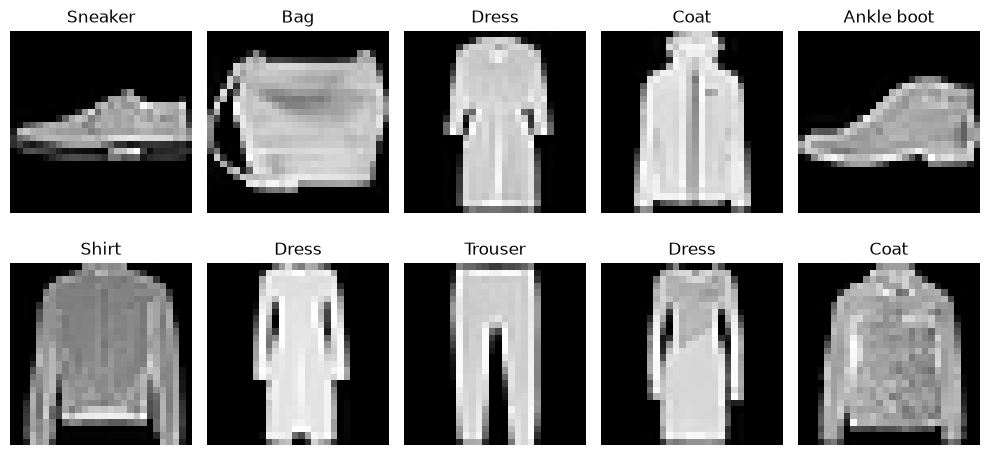

In [34]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].squeeze(), cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

#### **5. Model A — Standard CNN Architecture**

Model A is designed as a conventional CNN using standard 2D convolutional
operations followed by max-pooling layers.

##### ***Architecture***

| Layer | Configuration |
|---|---|
| Input | 28 × 28 × 1 |
| Conv2D | 16 filters, 3 × 3, ReLU |
| MaxPooling2D | 2 × 2 |
| Conv2D | 32 filters, 3 × 3, ReLU |
| MaxPooling2D | 2 × 2 |
| Conv2D | 64 filters, 3 × 3, ReLU |
| MaxPooling2D | 2 × 2 |
| Flatten | — |
| Dense | 64 units, ReLU |
| Output Dense | 10 units, Softmax |

The architecture follows the assignment requirement for Model A: standard
2D convolutional layers interleaved with max-pooling layers.

In [35]:
model_A = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Convolution block 1
    layers.Conv2D(
        filters=16,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Convolution block 2
    layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Convolution block 3
    layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model_A.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 7, 7, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 3, 3, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,874 (237.79 KB)

 Trainable params: 60,874 (237.79 KB)

 Non-trainable params: 0 (0.00 B)

##### ***5.1 Architecture Explanation***
The network progressively increases the number of convolutional filters from
16 to 32 and then to 64. This allows the network to learn increasingly complex
visual features.

##### **Convolutional layers**
The convolutional layers extract spatial features from the input image.
A 3 × 3 kernel is used because it provides a small receptive field while
keeping the number of parameters relatively low.

##### **Max-pooling layers**
A 2 × 2 max-pooling operation reduces the spatial dimensions by approximately
half after each convolutional block. This reduces the computational burden
of subsequent layers while retaining strong local features.

##### **Flatten layer**
After the three pooling operations, the feature map is flattened into a
one-dimensional vector before being passed to the fully connected classifier.

##### **Fully connected layers**
A 64-unit dense layer combines the extracted features for classification.
The final 10-unit layer corresponds to the 10 Fashion-MNIST classes.

#### ***5.2 Trainable Parameter Calculation***

For a standard convolutional layer:

$$
P = (K_h \times K_w \times C_{in} \times C_{out}) + C_{out}
$$

where:

* $K_h, K_w$ = kernel height and width
* $C_{in}$ = number of input channels
* $C_{out}$ = number of filters
* $C_{out}$ additional parameters correspond to the biases

##### **Conv2D Layer 1**

$$
(3 \times 3 \times 1 \times 16) + 16 = 160
$$

##### **Conv2D Layer 2**

$$
(3 \times 3 \times 16 \times 32) + 32 = 4,640
$$

##### **Conv2D Layer 3**

$$
(3 \times 3 \times 32 \times 64) + 64 = 18,496
$$

After three $2 \times 2$ pooling operations:

$$
28 \rightarrow 14 \rightarrow 7 \rightarrow 3
$$

Therefore, the final feature map is:

$$
3 \times 3 \times 64 = 576
$$

##### **Dense Layer**

$$
(576 \times 64) + 64 = 36,928
$$

##### **Output Layer**

$$
(64 \times 10) + 10 = 650
$$

##### **Total**

$$
\begin{aligned}
160 + 4,640 + 18,496 + 36,928 + 650
&= 60,874
\end{aligned}
$$

Therefore, Model A contains **60,874 trainable parameters**.


In [36]:
manual_parameter_count = (
    160 +       # Conv2D 1
    4640 +      # Conv2D 2
    18496 +     # Conv2D 3
    36928 +     # Dense 64
    650         # Output Dense 10
)

keras_parameter_count = model_A.count_params()

print(f"Manual parameter count: {manual_parameter_count:,}")
print(f"Keras parameter count:  {keras_parameter_count:,}")

assert manual_parameter_count == keras_parameter_count, (
    "Parameter count mismatch. Check the model architecture."
)

print("Parameter count verification: PASSED")

Manual parameter count: 60,874
Keras parameter count:  60,874
Parameter count verification: PASSED


#### ***5.3 Activation Function Selection***

##### ReLU
ReLU is computationally simple because it mainly requires a comparison with
zero and does not require an exponential calculation.

##### Softmax
Softmax is used only in the final output layer to convert the 10 output logits
into class probabilities.


#### **6. Optimizer Selection**
Adam is selected as the primary optimizer for Model A.

The selected optimizer will later be compared with:

1. Standard SGD
2. SGD with Momentum

In [37]:
# Baseline optimizer for Model A
learning_rate_A = 0.001

model_A.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=learning_rate_A
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model A compiled successfully.")
print("Optimizer: Adam")
print("Learning rate:", learning_rate_A)

Model A compiled successfully.
Optimizer: Adam
Learning rate: 0.001


#### **6.1 Optimizer Comparison**

Adam is used as the baseline optimizer. Its performance is compared with
standard Stochastic Gradient Descent (SGD) and SGD with Momentum.

All experiments use the same model architecture, training dataset,
validation dataset, batch size, and number of epochs.

The validation accuracy is used to compare optimizer performance.
The test dataset is reserved for the final evaluation of the selected model.

In [38]:
import time
import pandas as pd

OPTIMIZER_EPOCHS = 20
OPTIMIZER_BATCH_SIZE = 64

# Each experiment starts from a fresh model with new weights.
optimizer_configs = {
    "Adam": keras.optimizers.Adam(
        learning_rate=0.001
    ),
    "SGD": keras.optimizers.SGD(
        learning_rate=0.01
    ),
    "SGD with Momentum": keras.optimizers.SGD(
        learning_rate=0.01,
        momentum=0.9
    )
}

optimizer_results = []
optimizer_histories = {}

for optimizer_name, optimizer in optimizer_configs.items():

    print(f"\nTraining with optimizer: {optimizer_name}")

    # Reproducible initialization for each experiment
    keras.utils.set_random_seed(SEED)

    # Create a fresh model with the same architecture
    experiment_model = keras.models.clone_model(model_A)

    experiment_model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    start_time = time.time()

    experiment_history = experiment_model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=OPTIMIZER_EPOCHS,
        batch_size=OPTIMIZER_BATCH_SIZE,
        verbose=1
    )

    elapsed_time = time.time() - start_time

    # Record validation metrics, not test metrics
    best_val_accuracy = max(
        experiment_history.history["val_accuracy"]
    )

    final_val_accuracy = (
        experiment_history.history["val_accuracy"][-1]
    )

    final_val_loss = (
        experiment_history.history["val_loss"][-1]
    )

    optimizer_results.append({
        "Optimizer": optimizer_name,
        "Epochs": OPTIMIZER_EPOCHS,
        "Learning Rate": (
            0.001 if optimizer_name == "Adam" else 0.01
        ),
        "Momentum": (
            0.9 if optimizer_name == "SGD with Momentum"
            else 0.0
        ),
        "Best Validation Accuracy (%)":
            best_val_accuracy * 100,
        "Final Validation Accuracy (%)":
            final_val_accuracy * 100,
        "Final Validation Loss": final_val_loss,
        "Average Time per Epoch (s)":
            elapsed_time / OPTIMIZER_EPOCHS
    })

    optimizer_histories[optimizer_name] = (
        experiment_history.history
    )

    print(f"Best validation accuracy: "
          f"{best_val_accuracy * 100:.2f}%")
    print(f"Average epoch time: "
          f"{elapsed_time / OPTIMIZER_EPOCHS:.2f} seconds")

optimizer_comparison_df = pd.DataFrame(optimizer_results)

optimizer_comparison_df


Training with optimizer: Adam
Epoch 1/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 21s 27ms/step - accuracy: 0.7897 - loss: 0.5746 - val_accuracy: 0.8560 - val_loss: 0.4000
Epoch 2/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 30s 39ms/step - accuracy: 0.8648 - loss: 0.3730 - val_accuracy: 0.8708 - val_loss: 0.3534
Epoch 3/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 20s 26ms/step - accuracy: 0.8803 - loss: 0.3247 - val_accuracy: 0.8776 - val_loss: 0.3313
Epoch 4/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 21s 28ms/step - accuracy: 0.8925 - loss: 0.2933 - val_accuracy: 0.8853 - val_loss: 0.3103
Epoch 5/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 34s 44ms/step - accuracy: 0.9005 - loss: 0.2696 - val_accuracy: 0.8889 - val_loss: 0.3001
Epoch 6/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 33s 43ms/step - accuracy: 0.9075 - loss: 0.2504 - val_accuracy: 0.8904 - val_loss: 0.2975
Epoch 7/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 35s 45ms/step - accuracy: 0.9142 - loss: 0.2329 - val_accuracy: 0.8938 - val_loss: 0.2872
Epoch 8/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 39s 42ms/step - acc

,Optimizer,Epochs,Learning Rate,Momentum,Best Validation Accuracy (%),Final Validation Accuracy (%),Final Validation Loss,Average Time per Epoch (s)
0,Adam,20,0.001,0.0,89.838094,88.999999,0.398155,127.800173
1,SGD,20,0.010,0.0,88.457143,88.457143,0.325139,16.584121
2,SGD with Momentum,20,0.010,0.9,89.399999,88.790476,0.376300,14.878821


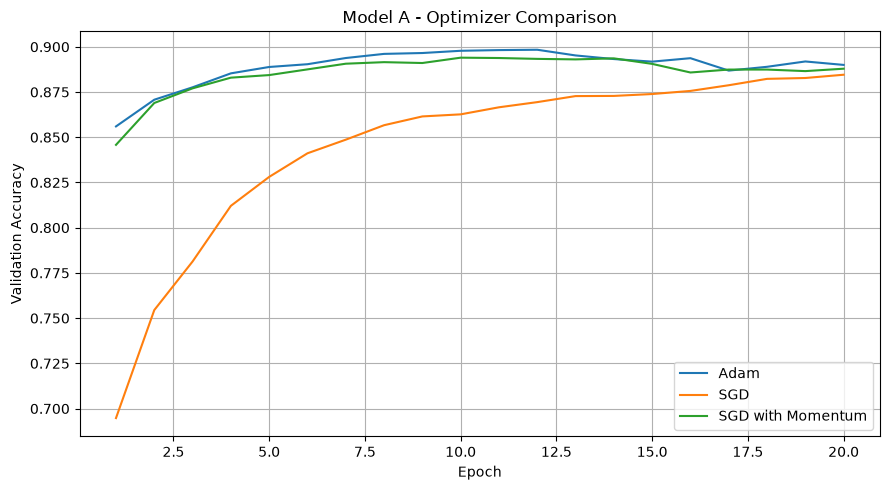

In [39]:
# Plot validation accuracy for all optimizers
plt.figure(figsize=(9, 5))

for optimizer_name, history in optimizer_histories.items():
    plt.plot(
        range(1, len(history["val_accuracy"]) + 1),
        history["val_accuracy"],
        label=optimizer_name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Model A - Optimizer Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [40]:
# Save optimizer comparison results
RESULTS_PATH = "../results/model_A"
os.makedirs(RESULTS_PATH, exist_ok=True)

optimizer_comparison_df.to_csv(
    os.path.join(
        RESULTS_PATH,
        "model_A_optimizer_comparison.csv"
    ),
    index=False
)

print("Optimizer comparison results saved.")

Optimizer comparison results saved.


#### **7. Model A Training**

The model is trained for **20 epochs**, satisfying the minimum training
requirement of the assignment. The validation set is used during training to monitor generalization
performance without using the test set for model development.


In [41]:
# Final Model A training

EPOCHS = 20
BATCH_SIZE = 64

start_time = time.time()

history_A = model_A.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

total_training_time_A = time.time() - start_time

completed_epochs_A = len(history_A.history["loss"])

average_epoch_time_A = (
    total_training_time_A / completed_epochs_A
)

print("\nFinal Model A training completed.")
print("Optimizer: Adam")
print(f"Completed epochs: {completed_epochs_A}")
print(f"Total training time: "
      f"{total_training_time_A:.2f} seconds")
print(f"Average time per epoch: "
      f"{average_epoch_time_A:.2f} seconds")

Epoch 1/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.7897 - loss: 0.5746 - val_accuracy: 0.8560 - val_loss: 0.4000
Epoch 2/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 0.8648 - loss: 0.3730 - val_accuracy: 0.8708 - val_loss: 0.3534
Epoch 3/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 16s 20ms/step - accuracy: 0.8803 - loss: 0.3247 - val_accuracy: 0.8776 - val_loss: 0.3313
Epoch 4/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.8925 - loss: 0.2933 - val_accuracy: 0.8853 - val_loss: 0.3103
Epoch 5/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - accuracy: 0.9005 - loss: 0.2696 - val_accuracy: 0.8889 - val_loss: 0.3001
Epoch 6/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 0.9075 - loss: 0.2504 - val_accuracy: 0.8904 - val_loss: 0.2975
Epoch 7/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.9142 - loss: 0.2329 - val_accuracy: 0.8938 - val_loss: 0.2872
Epoch 8/20
766/766 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - accuracy: 0.9206 - loss: 0.2178 - 

##### ***7.1 Training History***

The training history contains the loss and accuracy values recorded for both
the training and validation datasets at every epoch.

In [42]:
history_df_A = pd.DataFrame(history_A.history)
history_df_A.index = np.arange(1, EPOCHS + 1)
history_df_A.head()

,accuracy,loss,val_accuracy,val_loss
1,0.789714,0.574616,0.856000,0.399972
2,0.864755,0.372995,0.870762,0.353409
3,0.880306,0.324682,0.877619,0.331317
4,0.892531,0.293254,0.885333,0.310295
5,0.900510,0.269581,0.888857,0.300101


##### ***7.2 Training and Validation Loss***

The following graph shows how the training and validation loss changed during
the 20 training epochs.

A decreasing training loss indicates that the model is learning from the
training data. The validation loss provides an indication of how well the
learned model generalizes to unseen validation data.

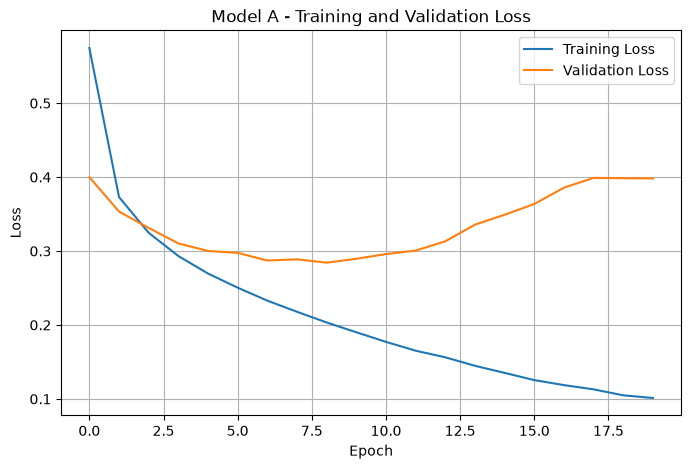

In [43]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_A.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_A.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model A - Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

##### ***7.3 Training and Validation Accuracy***

Although the assignment specifically requires loss curves, accuracy curves are
also plotted to make the training behaviour easier to interpret.

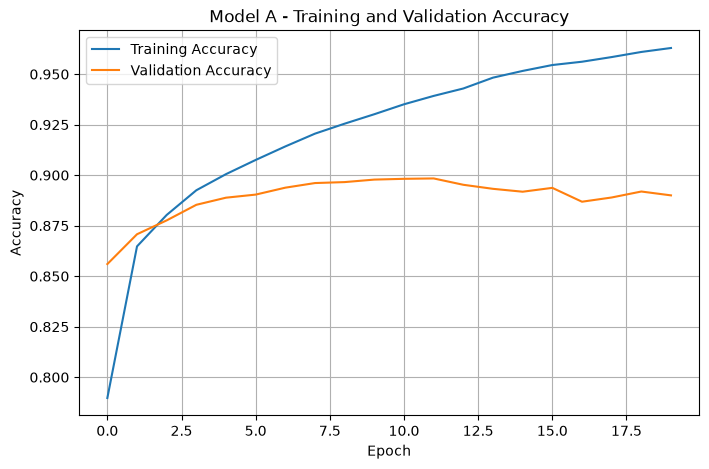

In [44]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_A.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_A.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model A - Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

#### **8. Model A Test Evaluation**
The test set is evaluated only after training is completed.
The following metrics are recorded:
- Test loss
- Test accuracy
- Precision
- Recall
- Confusion matrix

In [45]:
# Final test-set evaluation

test_loss_A, test_accuracy_A = model_A.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\n========== MODEL A TEST RESULTS ==========")
print(f"Test Loss:     {test_loss_A:.4f}")
print(f"Test Accuracy: {test_accuracy_A * 100:.2f}%")
print("==========================================")

329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8958 - loss: 0.3855

========== MODEL A TEST RESULTS ==========
Test Loss:     0.3855
Test Accuracy: 89.58%


In [46]:
# Generate predictions on the test set
y_pred_probability_A = model_A.predict(
    X_test,
    verbose=1
)

y_pred_A = np.argmax(
    y_pred_probability_A,
    axis=1
)

print("Predictions generated successfully.")
print("Prediction shape:", y_pred_A.shape)

329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
Predictions generated successfully.
Prediction shape: (10500,)


##### ***8.1 Precision and Recall***

In [47]:
# Precision and recall

precision_A = precision_score(
    y_test,
    y_pred_A,
    average="weighted",
    zero_division=0
)

recall_A = recall_score(
    y_test,
    y_pred_A,
    average="weighted",
    zero_division=0
)

macro_precision_A = precision_score(
    y_test,
    y_pred_A,
    average="macro",
    zero_division=0
)

macro_recall_A = recall_score(
    y_test,
    y_pred_A,
    average="macro",
    zero_division=0
)

print(f"Weighted Precision: {precision_A:.4f}")
print(f"Weighted Recall:    {recall_A:.4f}")
print(f"Macro Precision:    {macro_precision_A:.4f}")
print(f"Macro Recall:       {macro_recall_A:.4f}")

Weighted Precision: 0.8963
Weighted Recall:    0.8958
Macro Precision:    0.8963
Macro Recall:       0.8958


In [48]:
# Classification report
print(
    classification_report(
        y_test,
        y_pred_A,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

 T-shirt/top       0.85      0.83      0.84      1050
     Trouser       0.94      0.99      0.97      1050
    Pullover       0.78      0.91      0.84      1050
       Dress       0.92      0.86      0.89      1050
        Coat       0.83      0.84      0.84      1050
      Sandal       0.98      0.98      0.98      1050
       Shirt       0.78      0.67      0.72      1050
     Sneaker       0.98      0.92      0.95      1050
         Bag       0.98      0.97      0.97      1050
  Ankle boot       0.92      0.98      0.95      1050

    accuracy                           0.90     10500
   macro avg       0.90      0.90      0.89     10500
weighted avg       0.90      0.90      0.89     10500



##### ***8.2 Confusion Matrix***

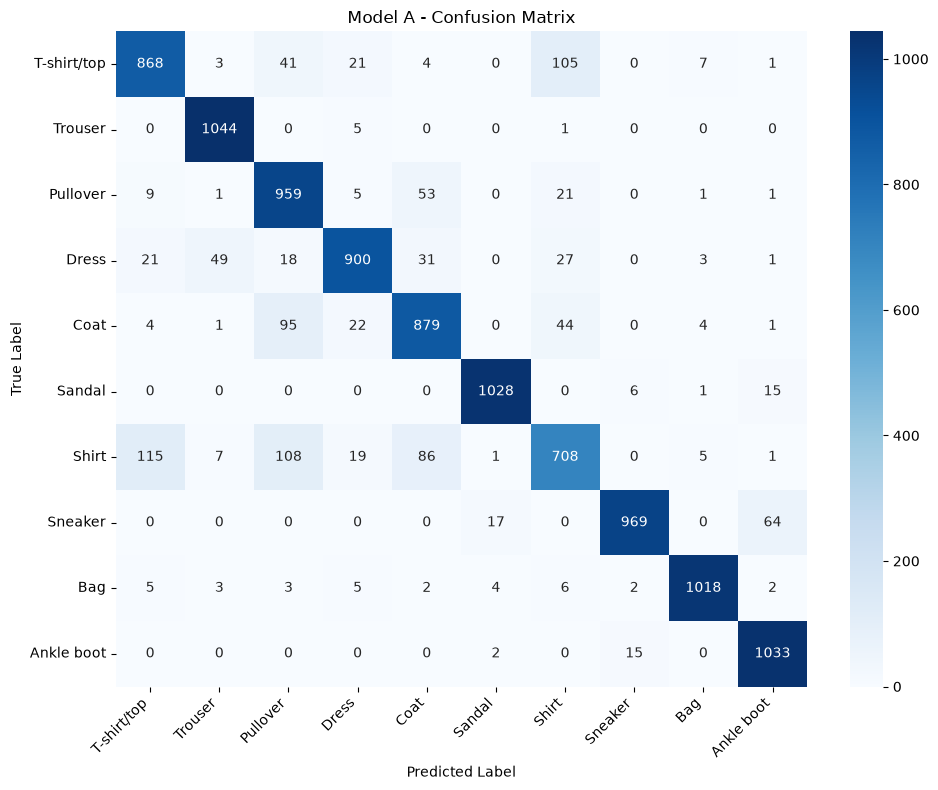

In [49]:
cm_A = confusion_matrix(
    y_test,
    y_pred_A
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_A,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Model A - Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

#### **9. Model Size and Computational Information**

In [50]:
# Save final Model A

from pathlib import Path
import os

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_A_PATH = MODEL_DIR / "model_A.keras"

model_A.save(str(MODEL_A_PATH))

model_A_file_size_bytes = MODEL_A_PATH.stat().st_size
model_A_file_size_kb = model_A_file_size_bytes / 1024
model_A_file_size_mb = model_A_file_size_bytes / (1024 ** 2)

print("Model A saved successfully.")
print("Model path:", MODEL_A_PATH.resolve())
print(f"Total parameters: {model_A.count_params():,}")
print(f"Model size: {model_A_file_size_kb:.2f} KB")
print(f"Model size: {model_A_file_size_mb:.4f} MB")
print(f"Average epoch time: {average_epoch_time_A:.2f} s")

Model A saved successfully.
Model path: C:\Desktop\SEM 5\Pattern\EN3150-CNN-Classification\models\model_A.keras
Total parameters: 60,874
Model size: 757.90 KB
Model size: 0.7401 MB
Average epoch time: 17.17 s


#### **10. Model A Summary**
The following table summarizes the main quantitative results of Model A.

In [51]:
# Final Model A results table

model_A_results = pd.DataFrame({
    "Model": ["Model A - Standard CNN"],
    "Total Parameters": [model_A.count_params()],
    "Model Size (KB)": [model_A_file_size_kb],
    "Model Size (MB)": [model_A_file_size_mb],
    "Training Time per Epoch (s)": [average_epoch_time_A],
    "Test Loss": [test_loss_A],
    "Test Accuracy (%)": [test_accuracy_A * 100],
    "Weighted Precision": [precision_A],
    "Weighted Recall": [recall_A],
    "Macro Precision": [macro_precision_A],
    "Macro Recall": [macro_recall_A]
})

model_A_results

,Model,Total Parameters,Model Size (KB),Model Size (MB),Training Time per Epoch (s),Test Loss,Test Accuracy (%),Weighted Precision,Weighted Recall,Macro Precision,Macro Recall
0,Model A - Standard CNN,60874,757.895508,0.740132,17.17231,0.385539,89.580953,0.896266,0.89581,0.896266,0.89581


In [52]:
# Verify final results
print("========== MODEL A FINAL RESULTS ==========")
print(f"Trainable parameters : {model_A.count_params():,}")
print(f"Model size           : {model_A_file_size_kb:.2f} KB")
print(f"Total training time  : {total_training_time_A:.2f} s")
print(f"Time per epoch       : {average_epoch_time_A:.2f} s")
print(f"Test loss            : {test_loss_A:.4f}")
print(f"Test accuracy        : {test_accuracy_A * 100:.2f}%")
print(f"Weighted precision   : {precision_A:.4f}")
print(f"Weighted recall      : {recall_A:.4f}")
print("===========================================")

========== MODEL A FINAL RESULTS ==========
Trainable parameters : 60,874
Model size           : 757.90 KB
Total training time  : 343.45 s
Time per epoch       : 17.17 s
Test loss            : 0.3855
Test accuracy        : 89.58%
Weighted precision   : 0.8963
Weighted recall      : 0.8958


In [53]:
# Save results for later comparison

import os

# Create results directory at project root
RESULTS_PATH = "../results/model_A"

os.makedirs(RESULTS_PATH, exist_ok=True)

# Save Model A summary results
model_A_results.to_csv(
    os.path.join(RESULTS_PATH, "model_A_results.csv"),
    index=False
)

# Save training history
history_df_A.to_csv(
    os.path.join(RESULTS_PATH, "model_A_training_history.csv"),
    index=False
)

print("Model A results saved successfully.")
print("Results saved to:")
print(os.path.abspath(RESULTS_PATH))

Model A results saved successfully.
Results saved to:
c:\Desktop\SEM 5\Pattern\EN3150-CNN-Classification\results\model_A


In [54]:
# Save Model A final results and training history

from pathlib import Path

RESULTS_DIR = Path("../results/model_A")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Summary results
model_A_results.to_csv(
    RESULTS_DIR / "model_A_results.csv",
    index=False
)

# Epoch-by-epoch training history
history_df_A.to_csv(
    RESULTS_DIR / "model_A_training_history.csv",
    index=False
)

# Final test predictions and true labels
predictions_df_A = pd.DataFrame({
    "True Label": y_test,
    "Predicted Label": y_pred_A
})

predictions_df_A.to_csv(
    RESULTS_DIR / "model_A_test_predictions.csv",
    index=False
)

# Confusion matrix
pd.DataFrame(
    cm_A,
    index=class_names,
    columns=class_names
).to_csv(
    RESULTS_DIR / "model_A_confusion_matrix.csv"
)

print("Final Model A outputs saved to:")
print(RESULTS_DIR.resolve())

Final Model A outputs saved to:
C:\Desktop\SEM 5\Pattern\EN3150-CNN-Classification\results\model_A


#### **11. Model A Interpretation**

Model A was implemented using three standard 2D convolutional layers with
16, 32, and 64 filters respectively. Each convolutional layer was followed
by a 2 × 2 max-pooling operation. The extracted features were then passed
through a 64-unit fully connected layer and a 10-unit output layer.

ReLU was selected for the hidden layers.  Softmax was retained for the final classification layer to
produce probabilities across the ten classes.

Adam with a learning rate of 0.001 was selected as the initial optimizer.
The model was trained for 20 epochs using the predefined training and validation sets.

Based on the training and validation curves, the behaviour of the model can
be assessed in terms of convergence and possible overfitting. The test-set
accuracy, precision, recall, and confusion matrix provide the final
classification performance.

The measured training time per epoch and saved model size will be used later
to compare Model A against Model B.

#### **12. Misclassified Examples**


Number of misclassified test images: 1094


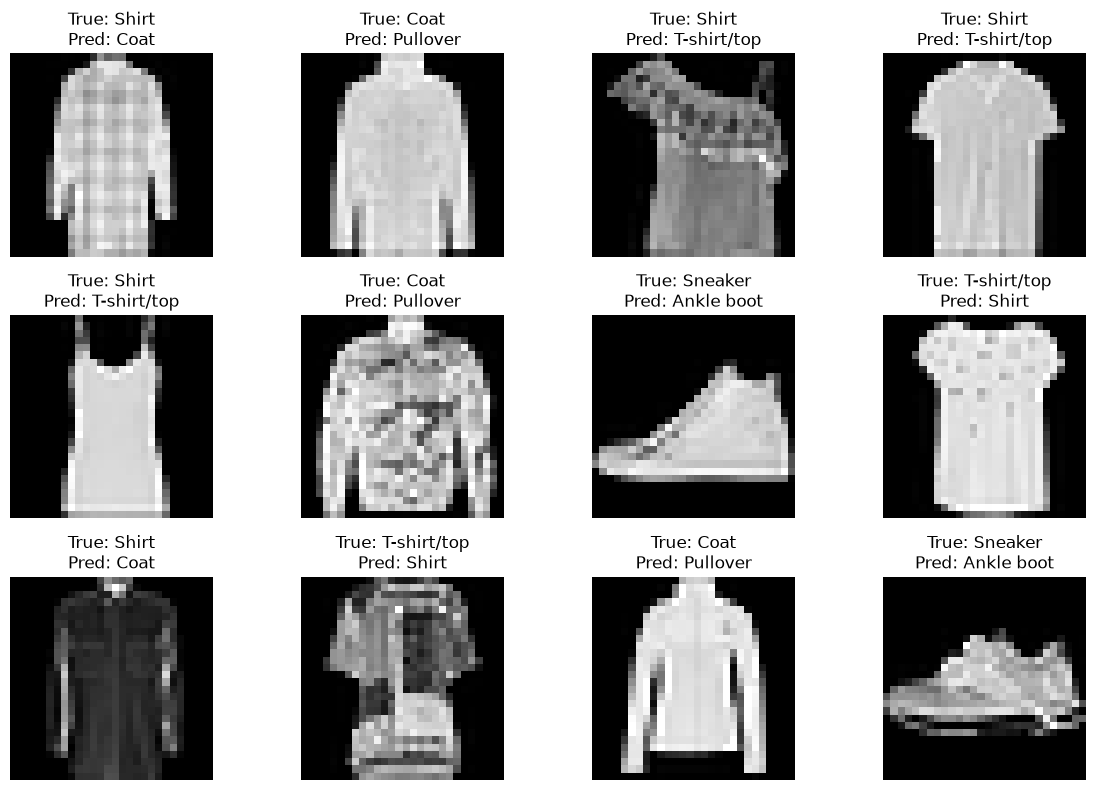

In [55]:
misclassified_indices = np.where(y_pred_A != y_test)[0]

print("Number of misclassified test images:", len(misclassified_indices))

plt.figure(figsize=(12, 8))

num_examples = min(12, len(misclassified_indices))

for i in range(num_examples):
    idx = misclassified_indices[i]

    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[idx].squeeze(), cmap="gray")

    plt.title(
        f"True: {class_names[y_test[idx]]}\n"
        f"Pred: {class_names[y_pred_A[idx]]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

#### **13. Conclusion**

Model A successfully implements the required standard CNN architecture using
standard 2D convolutions and max-pooling.

The model architecture, trainable parameter count, activation functions,
optimizer configuration, training behaviour, test performance, confusion
matrix, precision, recall, model size, and training time have been recorded.

The resulting Model A measurements will be used as the baseline for comparison
with Model B, which replaces standard convolutions with depthwise-separable
convolutions.

The next stage is to develop Model B while maintaining the same dataset
splits and evaluation methodology.